# 01 · Exploración de la línea de producción

**Proyecto:** Planta del Futuro — monitoreo predictivo de una línea de fresado.

En este notebook:
1. Cargamos el dataset **AI4I 2020** (10 000 ciclos de máquinas fresadoras).
2. Lo **limpiamos**: nombres en español, temperaturas en °C y validaciones.
3. **Simulamos la planta**: 5 máquinas, fecha y hora de cada ciclo, y turno.
4. Hacemos un **análisis exploratorio** (EDA) para entender cuándo y por qué fallan las máquinas.
5. Guardamos `data/processed/produccion_planta.csv`, que usarán Power BI y n8n.

> Toda la lógica vive en `src/planta/`. Aquí solo se llaman funciones y se explican los resultados.

## 0. Preparación

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from planta.data.carga import cargar_dataset_crudo
from planta.data.guardado import guardar_csv_procesado
from planta.data.limpieza import limpiar_dataset
from planta.features.simulacion import describir_secuencia_desgaste, simular_operacion_planta

# Estilo sobrio para todos los gráficos
COLOR_NORMAL = "#2a78d6"  # azul: operación normal / serie única
COLOR_FALLA = "#eb6834"   # naranja: fallas
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#a3a29b", "axes.grid": True, "grid.color": "#e4e3df",
    "axes.axisbelow": True, "axes.titlelocation": "left", "axes.titleweight": "bold",
    "font.size": 10,
})
pd.set_option("display.max_columns", 30)

## 1. Carga del dataset

`cargar_dataset_crudo()` lee la copia local de `data/raw/`. Si no existe, la descarga de UCI y la guarda.

In [2]:
datos_crudos = cargar_dataset_crudo()
print(f"{datos_crudos.shape[0]} filas x {datos_crudos.shape[1]} columnas")
datos_crudos.head()

10000 filas x 14 columnas


,UID,Product ID,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Limpieza

`limpiar_dataset()` hace cuatro cosas:
- Renombra las columnas a español `snake_case` con su unidad (`_c`, `_rpm`, `_nm`, `_min`).
- Convierte las temperaturas de **Kelvin a °C** (°C = K − 273.15).
- **Valida** que no haya valores nulos.
- **Valida** que no haya filas ni identificadores duplicados.

Si alguna validación falla, el proceso se detiene con un error en lugar de seguir con datos malos.

In [3]:
datos_limpios = limpiar_dataset(datos_crudos)
print("Nulos:", int(datos_limpios.isna().sum().sum()), "| Filas duplicadas:", int(datos_limpios.duplicated().sum()))
datos_limpios.head()

Nulos: 0 | Filas duplicadas: 0


,id_registro,id_producto,tipo_producto,temperatura_aire_c,temperatura_proceso_c,velocidad_rotacion_rpm,torque_nm,desgaste_herramienta_min,falla_maquina,falla_desgaste_herramienta,falla_disipacion_calor,falla_potencia,falla_sobreesfuerzo,falla_aleatoria
0,1,M14860,M,24.95,35.45,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,25.05,35.55,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,24.95,35.35,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,25.05,35.45,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,25.05,35.55,1408,40.0,9,0,0,0,0,0,0


## 3. ¿El desgaste de herramienta sigue un orden en el tiempo?

Antes de inventar fechas hay que saber si **el orden de las filas significa algo**.
Si el desgaste crece fila a fila, el dataset es como el historial de una línea de producción y debemos respetar ese orden.

In [4]:
resumen_desgaste = describir_secuencia_desgaste(datos_limpios["desgaste_herramienta_min"])
pd.Series(resumen_desgaste, name="valor").to_frame()

,valor
pasos_que_suben,9880.0
pasos_iguales,0.0
pasos_que_bajan,119.0
aumento_promedio_min,2.6
cambios_de_herramienta,119.0
vidas_de_herramienta,120.0
filas_promedio_por_vida,83.3


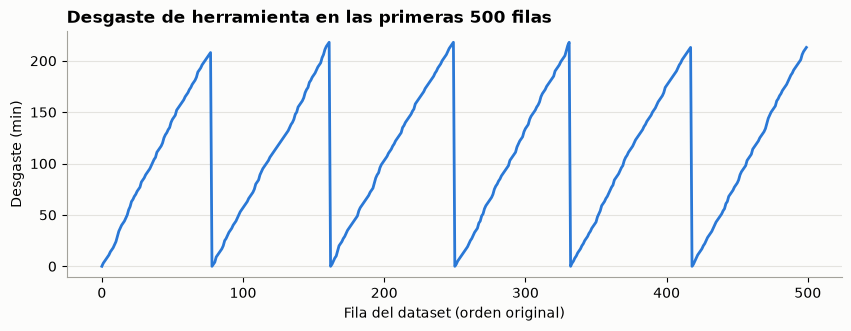

In [5]:
figura, eje = plt.subplots(figsize=(10, 3.2))
primeras_filas = datos_limpios.iloc[:500]
eje.plot(primeras_filas.index, primeras_filas["desgaste_herramienta_min"], color=COLOR_NORMAL, linewidth=2)
eje.set_title("Desgaste de herramienta en las primeras 500 filas")
eje.set_xlabel("Fila del dataset (orden original)")
eje.set_ylabel("Desgaste (min)")
eje.grid(axis="x", visible=False)
plt.show()

**Conclusión:** el desgaste **sí sigue un orden en el tiempo**.

- En 9 880 de 9 999 pasos el desgaste **sube** (entre 2 y 5 min cada vez) y nunca se queda igual.
- Las 119 veces que baja, **vuelve a 0**: es un **cambio de herramienta**. El gráfico tiene forma de "serrucho".
- En total hay **120 vidas de herramienta**, de unas 83 filas cada una, que llegan a unos 200–250 min antes del cambio.

Por eso las máquinas se asignan en **bloques contiguos**: si repartiéramos las filas al azar, romperíamos esa historia.

## 4. Simulación de la planta

`simular_operacion_planta()` agrega tres columnas:
- **`id_maquina`** (M01–M05): bloques contiguos de ~2000 filas. Cada corte se ajusta al cambio de herramienta más cercano, así **todas las máquinas empiezan con herramienta nueva**.
- **`fecha_hora`**: un ciclo cada 30 minutos por máquina, desde el 2026-09-01 06:00.
- **`turno`**: Mañana (06–14), Tarde (14–22) y Noche (22–06).

In [6]:
produccion = simular_operacion_planta(datos_limpios)
produccion.groupby("id_maquina").agg(
    ciclos=("id_registro", "size"),
    desde=("fecha_hora", "min"),
    hasta=("fecha_hora", "max"),
    desgaste_inicial_min=("desgaste_herramienta_min", "first"),
)

,ciclos,desde,hasta,desgaste_inicial_min
id_maquina,,,,
M01,1997,2026-09-01 06:00:00,2026-10-12 20:00:00,0
M02,2038,2026-09-01 06:00:00,2026-10-13 16:30:00,0
M03,1965,2026-09-01 06:00:00,2026-10-12 04:00:00,0
M04,2029,2026-09-01 06:00:00,2026-10-13 12:00:00,0
M05,1971,2026-09-01 06:00:00,2026-10-12 07:00:00,0


In [7]:
produccion["turno"].value_counts().reindex(["Mañana", "Tarde", "Noche"]).to_frame("ciclos")

,ciclos
turno,
Mañana,3360
Tarde,3331
Noche,3309


In [8]:
produccion.head()

,id_registro,id_maquina,fecha_hora,turno,id_producto,tipo_producto,temperatura_aire_c,temperatura_proceso_c,velocidad_rotacion_rpm,torque_nm,desgaste_herramienta_min,falla_maquina,falla_desgaste_herramienta,falla_disipacion_calor,falla_potencia,falla_sobreesfuerzo,falla_aleatoria
0,1,M01,2026-09-01 06:00:00,Mañana,M14860,M,24.95,35.45,1551,42.8,0,0,0,0,0,0,0
1,2,M01,2026-09-01 06:30:00,Mañana,L47181,L,25.05,35.55,1408,46.3,3,0,0,0,0,0,0
2,3,M01,2026-09-01 07:00:00,Mañana,L47182,L,24.95,35.35,1498,49.4,5,0,0,0,0,0,0
3,4,M01,2026-09-01 07:30:00,Mañana,L47183,L,25.05,35.45,1433,39.5,7,0,0,0,0,0,0
4,5,M01,2026-09-01 08:00:00,Mañana,L47184,L,25.05,35.55,1408,40.0,9,0,0,0,0,0,0


## 5. Análisis exploratorio

### 5.1 Distribuciones de las variables del proceso
Un histograma muestra **qué valores son comunes y cuáles son raros** en cada variable.

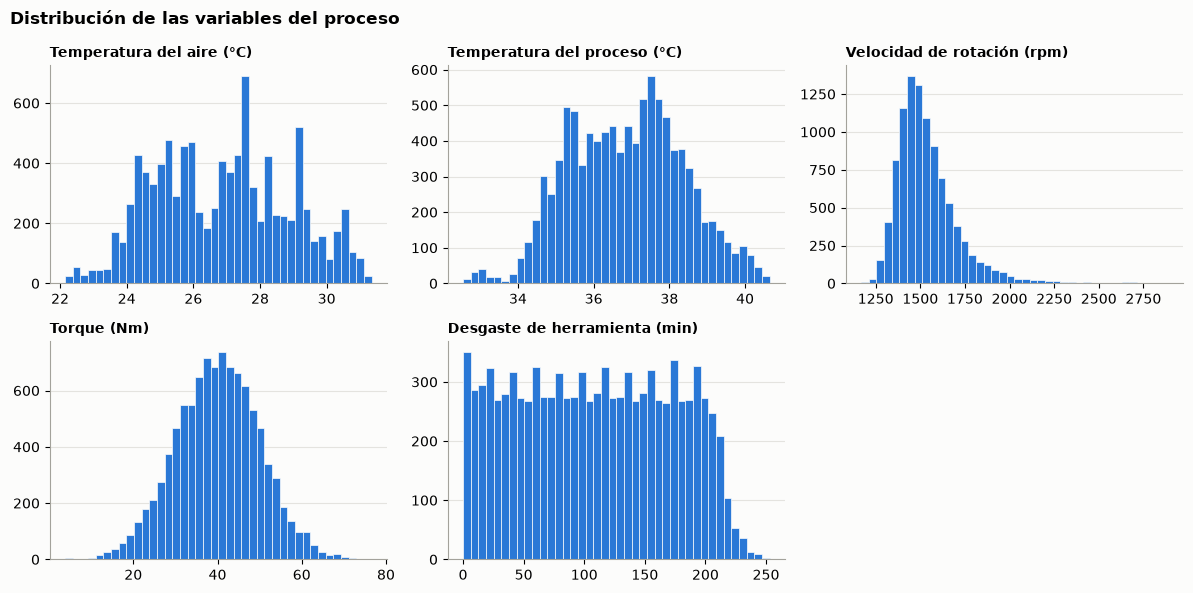

In [9]:
columnas_numericas = {
    "temperatura_aire_c": "Temperatura del aire (°C)",
    "temperatura_proceso_c": "Temperatura del proceso (°C)",
    "velocidad_rotacion_rpm": "Velocidad de rotación (rpm)",
    "torque_nm": "Torque (Nm)",
    "desgaste_herramienta_min": "Desgaste de herramienta (min)",
}
figura, ejes = plt.subplots(2, 3, figsize=(12, 6))
for eje, (columna, titulo) in zip(ejes.flat, columnas_numericas.items()):
    eje.hist(produccion[columna], bins=40, color=COLOR_NORMAL, edgecolor="#fcfcfb", linewidth=0.5)
    eje.set_title(titulo, fontsize=10)
    eje.grid(axis="x", visible=False)
ejes.flat[-1].set_visible(False)
figura.suptitle("Distribución de las variables del proceso", x=0.01, ha="left", fontweight="bold")
figura.tight_layout()
plt.show()

In [10]:
produccion[list(columnas_numericas)].describe().round(2)

,temperatura_aire_c,temperatura_proceso_c,velocidad_rotacion_rpm,torque_nm,desgaste_herramienta_min
count,10000.00,10000.00,10000.00,10000.00,10000.00
mean,26.85,36.86,1538.78,39.99,107.95
std,2.00,1.48,179.28,9.97,63.65
min,22.15,32.55,1168.00,3.80,0.00
25%,25.15,35.65,1423.00,33.20,53.00
50%,26.95,36.95,1503.00,40.10,108.00
75%,28.35,37.95,1612.00,46.80,162.00
max,31.35,40.65,2886.00,76.60,253.00


**Conclusión:**

- **Temperatura del proceso y torque** tienen forma de campana: la mayoría de los ciclos está cerca del promedio (36.9 °C y 40 Nm).
- **Temperatura del aire** es irregular, con varios picos. El aire cambia lentamente a lo largo del tiempo, así que **unos tramos de producción fueron más calurosos que otros**. Esto importa en la sección 5.5.
- **Velocidad de rotación** está cargada a la izquierda: casi todo entre 1 400 y 1 600 rpm, con pocos ciclos muy rápidos (hasta 2 886 rpm).
- **Desgaste de herramienta** es casi plano de 0 a 200 min y cae después: casi ninguna herramienta pasa de ~250 min porque **se reemplaza antes**.

### 5.2 Tasa de falla general y por tipo de producto
La **tasa de falla** es el porcentaje de ciclos que terminaron en falla de máquina.
El tipo de producto indica la calidad: **L** (baja), **M** (media) y **H** (alta).

In [11]:
print(f"Tasa de falla general: {produccion['falla_maquina'].mean():.2%} "
      f"({produccion['falla_maquina'].sum()} fallas en {len(produccion)} ciclos)")

por_producto = (
    produccion.groupby("tipo_producto")
    .agg(ciclos=("falla_maquina", "size"), fallas=("falla_maquina", "sum"))
    .reindex(["L", "M", "H"])
)
por_producto["tasa_falla_pct"] = (por_producto["fallas"] / por_producto["ciclos"] * 100).round(2)
por_producto

Tasa de falla general: 3.39% (339 fallas en 10000 ciclos)


,ciclos,fallas,tasa_falla_pct
tipo_producto,,,
L,6000,235,3.92
M,2997,83,2.77
H,1003,21,2.09


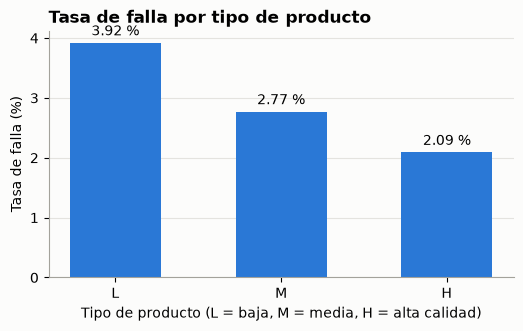

In [12]:
figura, eje = plt.subplots(figsize=(6, 3.2))
barras = eje.bar(por_producto.index, por_producto["tasa_falla_pct"], color=COLOR_NORMAL, width=0.55)
eje.bar_label(barras, fmt="%.2f %%", padding=3)
eje.set_title("Tasa de falla por tipo de producto")
eje.set_xlabel("Tipo de producto (L = baja, M = media, H = alta calidad)")
eje.set_ylabel("Tasa de falla (%)")
eje.grid(axis="x", visible=False)
plt.show()

**Conclusión:** a **menor calidad de producto, más fallas**.

- **L (baja):** 3.92 % → **M (media):** 2.77 % → **H (alta):** 2.09 %.
- Además, **L es el 60 % de la producción**, así que concentra 235 de las 339 fallas.
- Según la documentación del dataset, el límite de sobreesfuerzo es más bajo para productos L, por eso se rompen antes con el mismo esfuerzo.

La tasa general es de **3.39 %**: de cada 100 ciclos, solo 3 o 4 fallan. Son **datos desbalanceados**, y eso hay que tenerlo en cuenta en el modelo del Día 3.

### 5.3 Fallas por tipo de falla
El dataset distingue 5 causas:

| Columna | Sigla | Significado |
|---|---|---|
| `falla_desgaste_herramienta` | TWF | La herramienta se gastó demasiado |
| `falla_disipacion_calor` | HDF | El calor no se disipa (poca diferencia de temperatura y baja velocidad) |
| `falla_potencia` | PWF | La potencia (torque × velocidad) quedó fuera de rango |
| `falla_sobreesfuerzo` | OSF | Demasiado esfuerzo: desgaste × torque muy alto |
| `falla_aleatoria` | RNF | Falla al azar, sin causa en los sensores |

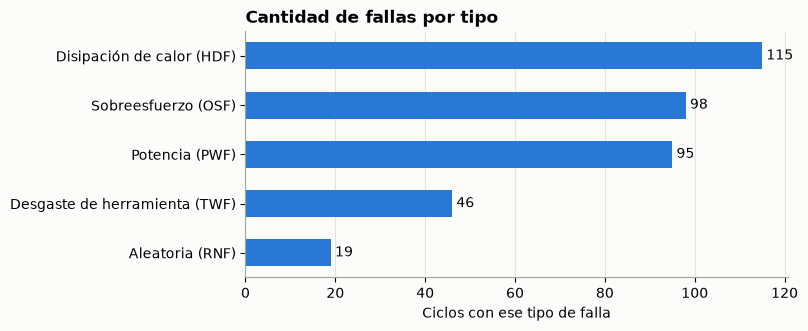

In [13]:
tipos_falla = {
    "falla_disipacion_calor": "Disipación de calor (HDF)",
    "falla_sobreesfuerzo": "Sobreesfuerzo (OSF)",
    "falla_potencia": "Potencia (PWF)",
    "falla_desgaste_herramienta": "Desgaste de herramienta (TWF)",
    "falla_aleatoria": "Aleatoria (RNF)",
}
conteo_por_tipo = produccion[list(tipos_falla)].sum().rename(index=tipos_falla).sort_values()

figura, eje = plt.subplots(figsize=(7, 3.2))
barras = eje.barh(conteo_por_tipo.index, conteo_por_tipo.values, color=COLOR_NORMAL, height=0.55)
eje.bar_label(barras, padding=3)
eje.set_title("Cantidad de fallas por tipo")
eje.set_xlabel("Ciclos con ese tipo de falla")
eje.grid(axis="y", visible=False)
plt.show()

In [14]:
tipos_por_fila = produccion[list(tipos_falla)].sum(axis=1)
pd.Series({
    "Fallas de máquina (falla_maquina = 1)": int(produccion["falla_maquina"].sum()),
    "Suma de fallas por tipo": int(conteo_por_tipo.sum()),
    "Fallas con más de un tipo a la vez": int((tipos_por_fila > 1).sum()),
    "Fallas de máquina sin tipo registrado": int(((produccion["falla_maquina"] == 1) & (tipos_por_fila == 0)).sum()),
    "Falla aleatoria sin falla de máquina": int(((produccion["falla_aleatoria"] == 1) & (produccion["falla_maquina"] == 0)).sum()),
}, name="ciclos").to_frame()

,ciclos
Fallas de máquina (falla_maquina = 1),339
Suma de fallas por tipo,373
Fallas con más de un tipo a la vez,24
Fallas de máquina sin tipo registrado,9
Falla aleatoria sin falla de máquina,18


**Conclusión:**

- La causa más común es **disipación de calor (115)**, seguida de **sobreesfuerzo (98)** y **potencia (95)**. El desgaste solo (46) y las fallas aleatorias (19) son menos frecuentes.
- La suma por tipo (373) es **mayor** que las fallas de máquina (339) porque **24 fallas tienen más de una causa a la vez**.
- Hay **dos detalles de calidad de datos** del dataset original:
  - **9 fallas de máquina** no tienen ninguna causa marcada.
  - **18 fallas aleatorias** están marcadas sin que la máquina haya fallado.

Por eso, para predecir en el Día 3 usaremos **`falla_maquina`** como la variable objetivo, y no la suma de las causas.

### 5.4 Relación entre torque, desgaste y fallas
Cada punto es un ciclo. Los puntos **naranjas** son ciclos con falla.

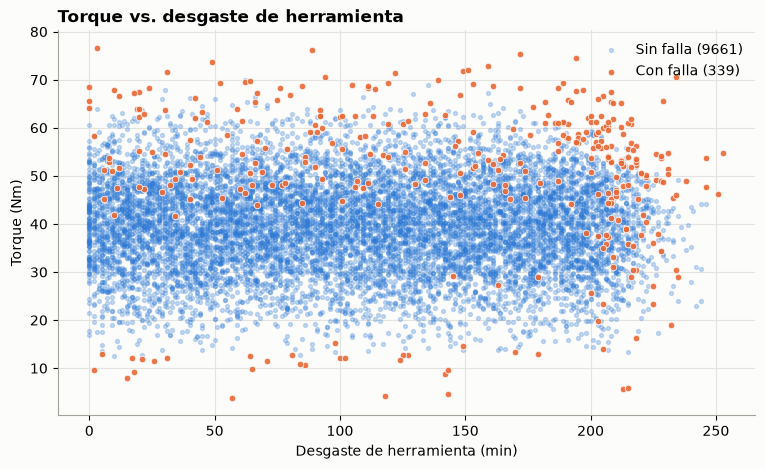

In [15]:
sin_falla = produccion[produccion["falla_maquina"] == 0]
con_falla = produccion[produccion["falla_maquina"] == 1]

figura, eje = plt.subplots(figsize=(9, 5))
eje.scatter(sin_falla["desgaste_herramienta_min"], sin_falla["torque_nm"], s=8, alpha=0.25,
            color=COLOR_NORMAL, label=f"Sin falla ({len(sin_falla)})")
eje.scatter(con_falla["desgaste_herramienta_min"], con_falla["torque_nm"], s=22, alpha=0.9,
            color=COLOR_FALLA, edgecolor="#fcfcfb", linewidth=0.6, label=f"Con falla ({len(con_falla)})")
eje.set_title("Torque vs. desgaste de herramienta")
eje.set_xlabel("Desgaste de herramienta (min)")
eje.set_ylabel("Torque (Nm)")
eje.legend(loc="upper right", frameon=False)
plt.show()

In [16]:
def tasa_falla_por_rangos(datos: pd.DataFrame, columna: str, limites: list[float]) -> pd.DataFrame:
    """Tasa de falla (%) por rangos de una variable."""
    rangos = pd.cut(datos[columna], bins=limites, right=False)
    tabla = datos.groupby(rangos, observed=True)["falla_maquina"].agg(ciclos="size", fallas="sum")
    tabla["tasa_falla_pct"] = (tabla["fallas"] / tabla["ciclos"] * 100).round(2)
    return tabla

tasa_falla_por_rangos(produccion, "torque_nm", [0, 20, 30, 40, 50, 60, 80])

,ciclos,fallas,tasa_falla_pct
torque_nm,,,
"[0, 20)",228,34,14.91
"[20, 30)",1348,9,0.67
"[30, 40)",3364,19,0.56
"[40, 50)",3487,66,1.89
"[50, 60)",1334,111,8.32
"[60, 80)",239,100,41.84


In [17]:
tasa_falla_por_rangos(produccion, "desgaste_herramienta_min", [0, 50, 100, 150, 200, 260])

,ciclos,fallas,tasa_falla_pct
desgaste_herramienta_min,,,
"[0, 50)",2349,52,2.21
"[50, 100)",2271,51,2.25
"[100, 150)",2290,52,2.27
"[150, 200)",2289,61,2.66
"[200, 260)",801,123,15.36


**Conclusión:** las fallas se concentran en los **extremos**.

**Torque:**
- Entre 20 y 40 Nm, la tasa de falla es menor al **1 %**: es la zona segura.
- Por encima de 60 Nm sube a **41.84 %**: casi 1 de cada 2 ciclos falla (sobreesfuerzo y potencia).
- Por debajo de 20 Nm también sube, a **14.91 %**: poco torque con mucha velocidad también es una potencia fuera de rango.

**Desgaste:**
- Hasta 200 min la tasa de falla se mantiene estable en **~2.2–2.7 %**.
- Desde 200 min salta a **15.36 %**: la herramienta llega al final de su vida.

En el gráfico, los puntos naranjas forman bandas **arriba** (torque alto), **abajo** (torque bajo) y a la **derecha** (desgaste alto). Ninguna variable sola explica las fallas; **la combinación de torque y desgaste sí**. Esto es justo lo que un modelo de IA puede aprender.

### 5.5 Fallas por máquina simulada

In [18]:
por_maquina = produccion.groupby("id_maquina").agg(
    ciclos=("falla_maquina", "size"),
    fallas=("falla_maquina", "sum"),
    temp_aire_prom_c=("temperatura_aire_c", "mean"),
)
por_maquina["tasa_falla_pct"] = (por_maquina["fallas"] / por_maquina["ciclos"] * 100).round(2)
por_maquina["fallas_calor_hdf"] = produccion.groupby("id_maquina")["falla_disipacion_calor"].sum()
por_maquina["dif_temp_prom_c"] = (
    (produccion["temperatura_proceso_c"] - produccion["temperatura_aire_c"]).groupby(produccion["id_maquina"]).mean()
)
por_maquina.round(2)

,ciclos,fallas,temp_aire_prom_c,tasa_falla_pct,fallas_calor_hdf,dif_temp_prom_c
id_maquina,,,,,,
M01,1997,52,24.55,2.60,0,10.66
M02,2038,53,27.44,2.60,7,9.23
M03,1965,150,29.57,7.63,108,8.91
M04,2029,46,27.51,2.27,0,10.22
M05,1971,38,25.22,1.93,0,10.99


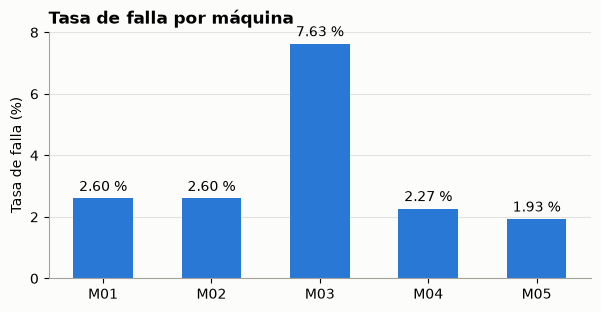

In [19]:
figura, eje = plt.subplots(figsize=(7, 3.2))
barras = eje.bar(por_maquina.index, por_maquina["tasa_falla_pct"], color=COLOR_NORMAL, width=0.55)
eje.bar_label(barras, fmt="%.2f %%", padding=3)
eje.set_title("Tasa de falla por máquina")
eje.set_ylabel("Tasa de falla (%)")
eje.grid(axis="x", visible=False)
plt.show()

**Conclusión:** **M03 es la máquina problema**.

- Su tasa de falla es **7.63 %**, unas **3 veces** la del resto (1.93 %–2.60 %).
- **108 de sus 150 fallas son por disipación de calor**. Las demás máquinas casi no tienen este tipo de falla.
- La razón está en los datos: a M03 le tocó el tramo con el **aire más caliente (29.57 °C en promedio)** y la **menor diferencia entre proceso y aire (8.91 °C)**. Con poca diferencia de temperatura, el calor no se disipa.

> **Para ser transparentes:** la máquina es simulada. Lo **real** es que ese tramo del dataset tuvo condiciones más calurosas. En una planta, la recomendación sería **revisar la ventilación o refrigeración de M03**.

## 6. Guardar el resultado

`guardar_csv_procesado()` escribe el CSV con el **contrato de datos**: UTF-8, separador coma y fechas ISO 8601 (`2026-09-01T06:00:00`).
Power BI y n8n leen este archivo, así que sus nombres de columna no deben cambiar.

In [20]:
ruta = guardar_csv_procesado(produccion)
print("Guardado en:", ruta.relative_to(ruta.parents[2]))
print(f"{len(produccion)} filas x {produccion.shape[1]} columnas")
print(list(produccion.columns))

Guardado en: data\processed\produccion_planta.csv
10000 filas x 17 columnas
['id_registro', 'id_maquina', 'fecha_hora', 'turno', 'id_producto', 'tipo_producto', 'temperatura_aire_c', 'temperatura_proceso_c', 'velocidad_rotacion_rpm', 'torque_nm', 'desgaste_herramienta_min', 'falla_maquina', 'falla_desgaste_herramienta', 'falla_disipacion_calor', 'falla_potencia', 'falla_sobreesfuerzo', 'falla_aleatoria']


## 7. Conclusiones generales

1. **Los datos están limpios:** 10 000 ciclos, sin nulos ni duplicados, con nombres en español y temperaturas en °C.
2. **El orden de las filas es temporal:** el desgaste crece y se reinicia 119 veces (cambios de herramienta). La simulación respeta ese orden y cada máquina empieza con herramienta nueva.
3. **Las fallas son raras (3.39 %).** Un modelo que siempre diga "no va a fallar" acertaría el 96.6 % de las veces y no serviría para nada. En el Día 3 hay que medir el modelo con métricas que miren las fallas (como *recall*), no solo el porcentaje de aciertos.
4. **Las variables que más se relacionan con las fallas** son el **torque** (extremos altos y bajos), el **desgaste** (más de 200 min), la **diferencia de temperatura** y la **velocidad**. Serán las entradas del modelo.
5. **Los productos de baja calidad (L) fallan más** (3.92 % frente a 2.09 % de los H).
6. **M03 concentra las fallas por calor:** es un buen caso para mostrar en el dashboard y en las alertas de n8n.

**Siguiente paso (Día 3):** calcular el **OEE** por máquina y turno, y entrenar el modelo de predicción de fallas.